# Tea Leaf Disease Classifier - VGG16 Challenger (vs ResNet18)

**What this notebook does, in plain words:** `train_tea_disease_classifier.ipynb`
already trained a ResNet18 model and it's registered in MLflow as
`tea-disease-resnet18`. This notebook asks: would a different, older,
heavier architecture - **VGG16** - do better? Instead of guessing, we
train it as a completely separate "challenger" model, on the *exact same*
data split as the ResNet18 run, and compare them properly at the end -
not just one accuracy number, but per-class performance and size/speed too
(a bigger model that's barely more accurate but much slower is often not
worth shipping).

**This is the industry pattern for "should we swap the production model's
architecture?"**: train the challenger separately, never touch the
currently-deployed model, compare offline first, and only then think about
rolling it out gradually. This notebook covers the "train it" and "compare
it" steps - rollout (shadow traffic, canary, aliasing) is a separate,
later decision once the offline numbers justify it.

**One deliberate change from ResNet18's run:** VGG16 is roughly 3-6x
slower per image on CPU than ResNet18, even though we're only training its
final layer - every forward pass still has to run through VGG16's much
bigger stack of convolutions. Training for the same 6 epochs ResNet18 used
would take well over 30-60 minutes here; this run uses **3 epochs**
instead, to get a first result faster. That makes this comparison *less*
strict than a same-budget one - note that honestly when reading the
results, and bump `EPOCHS` back to 6 and rerun if you want the fairer
comparison.


## 1. Setup

Identical to the ResNet18 notebook: same seed, same libraries, plus
`models.vgg16` instead of (in addition to) `models.resnet18`.


In [1]:
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)


Using device: cpu


## 2. Where the data lives, and the settings we'll use

**What we're doing here:** same dataset folder, same `model/` output
folder as the ResNet18 notebook (this run saves to a differently-named
file, so it won't overwrite the ResNet18 one). `IMG_SIZE`, `VAL_SIZE`,
`TEST_SIZE`, and `SEED` are copied **identically** from the ResNet18
notebook - that's what makes the train/val/test split below come out
exactly the same for both models, which is what makes the comparison fair.
`EPOCHS` is lower, for the reason explained above.


In [2]:
DATA_DIR = Path("dataset/data/teaLeafBD/teaLeafBD")
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

IMG_SIZE = 224          # same as ResNet18 notebook
BATCH_SIZE = 32         # same as ResNet18 notebook
EPOCHS = 3              # lower than ResNet18's 6 - see the note above
LEARNING_RATE = 1e-3    # same as ResNet18 notebook
VAL_SIZE = 0.15         # same as ResNet18 notebook
TEST_SIZE = 0.15        # same as ResNet18 notebook

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

assert DATA_DIR.exists(), f"Dataset not found at {DATA_DIR}. Run dataset/download_dataset.py first."


## 3. Classes

**What we're doing here:** same 7 classes as the ResNet18 notebook - just
confirming we're looking at the same dataset.


In [3]:
class_dirs = sorted([d for d in DATA_DIR.iterdir() if d.is_dir()])
class_names = [d.name for d in class_dirs]
print(f"Found {len(class_names)} classes:")
for c in class_names:
    print(" -", c)


Found 7 classes:
 - 1. Tea algal leaf spot
 - 2. Brown Blight
 - 3. Gray Blight
 - 4. Helopeltis
 - 5. Red spider
 - 6. Green mirid bug
 - 7. Healthy leaf


## 4. Build the file list and split it into train / validation / test

**What we're doing here:** the exact same splitting code as the ResNet18
notebook, with the exact same `SEED`, `VAL_SIZE`, and `TEST_SIZE`. Given
the dataset folder hasn't changed, this produces the **identical** three
piles of photos as the ResNet18 run - same training data, same held-out
test set. That's the whole point: any difference in the final numbers
comes from the architecture, not from a lucky or unlucky split.


In [4]:
all_paths, all_labels = [], []
for idx, d in enumerate(class_dirs):
    for f in d.glob("*.*"):
        all_paths.append(str(f))
        all_labels.append(idx)

print(f"Total images: {len(all_paths)}")

train_paths, rest_paths, train_labels, rest_labels = train_test_split(
    all_paths, all_labels, test_size=(VAL_SIZE + TEST_SIZE),
    stratify=all_labels, random_state=SEED,
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    rest_paths, rest_labels, test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
    stratify=rest_labels, random_state=SEED,
)

print(f"Train: {len(train_paths)}  Val: {len(val_paths)}  Test: {len(test_paths)}")


Total images: 5276
Train: 3693  Val: 791  Test: 792


## 5. Data augmentation and preprocessing

Identical to the ResNet18 notebook - same augmentation recipe, same
ImageNet normalization (VGG16 was pretrained on ImageNet too, so it
expects the same input convention as ResNet18).


In [5]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


## 6. Dataset and DataLoader

Identical to the ResNet18 notebook.


In [6]:
class TeaLeafDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        img = self.transform(img)
        return img, self.labels[idx]


train_ds = TeaLeafDataset(train_paths, train_labels, train_transform)
val_ds = TeaLeafDataset(val_paths, val_labels, eval_transform)
test_ds = TeaLeafDataset(test_paths, test_labels, eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Batches -> train: {len(train_loader)}  val: {len(val_loader)}  test: {len(test_loader)}")


Batches -> train: 116  val: 25  test: 25


## 7. The model: VGG16 with transfer learning

**What we're doing here:** same transfer-learning idea as ResNet18 - take
a model pretrained on ImageNet, freeze everything, replace the final
decision layer with a fresh one sized to our 7 classes, and only train
that new layer.

**Where VGG16 differs from ResNet18 architecturally:** VGG16's "deciding"
part (`model.classifier`) isn't a single layer like ResNet18's `model.fc`
- it's a small stack of three `Linear` layers (`25088 -> 4096 -> 4096 ->
1000` for the original 1000 ImageNet categories). We only replace the
*last* one (`classifier[6]`) with `Linear(4096, 7)`, so the two big
`4096`-wide layers before it stay frozen and pretrained too - only the
final 7-way decision is learned from scratch, exactly like ResNet18's
single `fc` layer.


In [7]:
vgg_model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)

# Freeze everything, same as the ResNet18 notebook
for param in vgg_model.parameters():
    param.requires_grad = False

# Replace only the final Linear layer of the 3-layer classifier head
in_features = vgg_model.classifier[6].in_features
vgg_model.classifier[6] = nn.Linear(in_features, len(class_names))

vgg_model = vgg_model.to(DEVICE)

vgg_trainable = sum(p.numel() for p in vgg_model.parameters() if p.requires_grad)
vgg_total = sum(p.numel() for p in vgg_model.parameters())
print(f"VGG16 trainable parameters: {vgg_trainable:,} / {vgg_total:,} total")
print("(For comparison, ResNet18 was 3,591 trainable / 11,180,103 total - "
      "VGG16's full network is roughly 12x bigger.)")


VGG16 trainable parameters: 28,679 / 134,289,223 total
(For comparison, ResNet18 was 3,591 trainable / 11,180,103 total - VGG16's full network is roughly 12x bigger.)


## 8. Loss function and optimizer

Same approach as ResNet18: only the new final layer's weights go to the
optimizer.


In [8]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(vgg_model.classifier[6].parameters(), lr=LEARNING_RATE)


## 9. Track this run with MLflow - same experiment, different run

**What we're doing here:** logging to the **same** `tea-disease-classification`
experiment the ResNet18 notebook uses (same shared store too), so both
models' runs show up side by side in the same MLflow UI. We tag this run's
`architecture` as `vgg16-frozen-backbone` and log the parameter counts
from above as params too - that's the "model size" half of the comparison,
captured properly instead of just remembered.


In [9]:
import mlflow
import mlflow.pytorch
from pathlib import Path as _Path

_SHARED_MLFLOW_DB = (_Path("..") / "mlflow" / "mlflow.db").resolve()
mlflow.set_tracking_uri(f"sqlite:///{_SHARED_MLFLOW_DB}")
mlflow.set_experiment("tea-disease-classification")

run = mlflow.start_run(run_name="vgg16-frozen-backbone")
mlflow.log_params({
    "architecture": "vgg16-frozen-backbone",
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "val_size": VAL_SIZE,
    "test_size": TEST_SIZE,
    "seed": SEED,
    "num_classes": len(class_names),
    "class_names": ", ".join(class_names),
    "trainable_params": vgg_trainable,
    "total_params": vgg_total,
})
print(f"MLflow run started: {run.info.run_id}")


MLflow run started: c78867ad3d12451c82971a8a5df978a0


## 10. Train the model

Same training loop shape as ResNet18, with one addition: we time each
epoch and log it (`epoch_seconds`) - that's the "speed" half of the
comparison, measured on this exact machine instead of quoted from a
benchmark somewhere else.


In [10]:
def run_epoch(loader, train_mode):
    vgg_model.train() if train_mode else vgg_model.eval()
    running_loss, correct, total = 0.0, 0, 0

    context = torch.enable_grad() if train_mode else torch.no_grad()
    with context:
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            if train_mode:
                optimizer.zero_grad()

            outputs = vgg_model(images)
            loss = criterion(outputs, labels)

            if train_mode:
                loss.backward()
                optimizer.step()

            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += images.size(0)

    return running_loss / total, correct / total


history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
best_state = None
training_start = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()
    train_loss, train_acc = run_epoch(train_loader, train_mode=True)
    val_loss, val_acc = run_epoch(val_loader, train_mode=False)
    epoch_seconds = time.time() - epoch_start

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    mlflow.log_metrics({
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "epoch_seconds": epoch_seconds,
    }, step=epoch)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = {k: v.cpu().clone() for k, v in vgg_model.state_dict().items()}

    print(f"Epoch {epoch}/{EPOCHS} - "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.3f} - "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.3f} - "
          f"({epoch_seconds:.1f}s)")

total_train_seconds = time.time() - training_start
vgg_model.load_state_dict(best_state)
mlflow.log_metric("best_val_acc", best_val_acc)
mlflow.log_metric("total_train_seconds", total_train_seconds)
print(f"\nBest validation accuracy: {best_val_acc:.3f}  (total training time: {total_train_seconds:.0f}s)")


Epoch 1/3 - train_loss=1.3845 train_acc=0.491 - val_loss=1.0118 val_acc=0.641 - (620.1s)
Epoch 2/3 - train_loss=1.1445 train_acc=0.596 - val_loss=0.9338 val_acc=0.664 - (590.2s)
Epoch 3/3 - train_loss=1.1188 train_acc=0.593 - val_loss=0.9303 val_acc=0.647 - (555.3s)

Best validation accuracy: 0.664  (total training time: 1766s)


## 11. Look at the training curves

Same idea as the ResNet18 notebook - watch for train accuracy pulling
ahead of validation accuracy, which would mean overfitting.


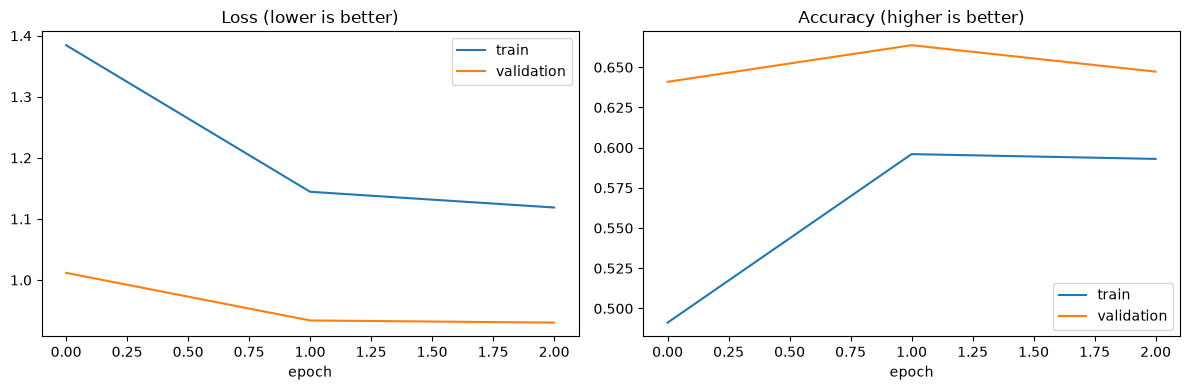

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="validation")
axes[0].set_title("Loss (lower is better)")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["val_acc"], label="validation")
axes[1].set_title("Accuracy (higher is better)")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.tight_layout()
plt.show()


## 12. Final evaluation on the test set

Same test set the ResNet18 notebook used (see section 4). This time we
also log **per-class** precision/recall/F1 as individual MLflow metrics,
not just the text report - that's what makes a real side-by-side
per-class comparison possible later, instead of eyeballing two text
blocks.


In [12]:
vgg_model.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = vgg_model(images)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_true.extend(labels.numpy())

test_accuracy = accuracy_score(all_true, all_preds)
report_text = classification_report(all_true, all_preds, target_names=class_names)
report_dict = classification_report(all_true, all_preds, target_names=class_names, output_dict=True)
print(f"Test accuracy: {test_accuracy:.3f}\n")
print(report_text)

mlflow.log_metric("test_accuracy", test_accuracy)
mlflow.log_metric("macro_f1", report_dict["macro avg"]["f1-score"])
mlflow.log_metric("weighted_f1", report_dict["weighted avg"]["f1-score"])
mlflow.log_text(report_text, "classification_report.txt")

# Per-class metrics, with names MLflow will accept (no dots/spaces)
for cname in class_names:
    slug = cname.lower().replace(" ", "_").replace(".", "").replace("-", "_")
    mlflow.log_metrics({
        f"precision_{slug}": report_dict[cname]["precision"],
        f"recall_{slug}": report_dict[cname]["recall"],
        f"f1_{slug}": report_dict[cname]["f1-score"],
    })


Test accuracy: 0.655

                        precision    recall  f1-score   support

1. Tea algal leaf spot       0.55      0.50      0.53        62
       2. Brown Blight       0.63      0.34      0.44        76
        3. Gray Blight       0.60      0.63      0.62       152
         4. Helopeltis       0.51      0.69      0.59        91
         5. Red spider       0.47      0.49      0.48        77
    6. Green mirid bug       0.72      0.78      0.75       193
       7. Healthy leaf       0.94      0.81      0.87       141

              accuracy                           0.66       792
             macro avg       0.63      0.61      0.61       792
          weighted avg       0.67      0.66      0.65       792



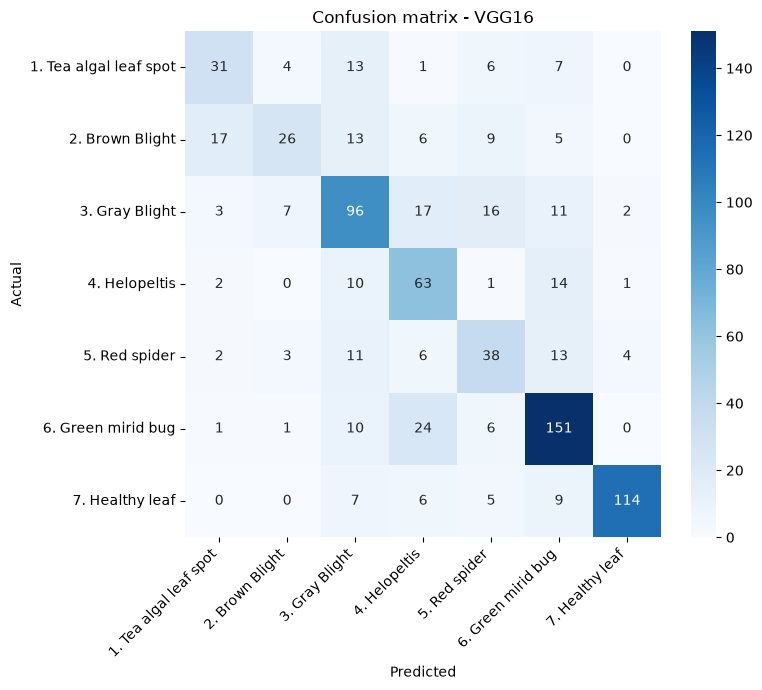

In [13]:
cm = confusion_matrix(all_true, all_preds)
fig = plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix - VGG16")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
mlflow.log_figure(fig, "confusion_matrix.png")
plt.show()


## 13. Measure inference speed

**What we're doing here:** timing single-photo predictions (batch size 1,
the way a real request would arrive) to get a concrete "milliseconds per
photo" number on this machine - not a vibe ("VGG feels slower"), an actual
measurement we can compare against ResNet18's.


In [14]:
def measure_inference_ms(model, paths, transform, n=30):
    model.eval()
    samples = [transform(Image.open(p).convert("RGB")).unsqueeze(0).to(DEVICE) for p in paths[:n]]
    with torch.no_grad():
        start = time.time()
        for sample in samples:
            model(sample)
        elapsed = time.time() - start
    return (elapsed / len(samples)) * 1000  # ms per image


vgg_inference_ms = measure_inference_ms(vgg_model, test_paths, eval_transform)
mlflow.log_metric("inference_ms_per_image", vgg_inference_ms)
print(f"VGG16 inference: {vgg_inference_ms:.1f} ms/image (CPU, batch size 1)")


VGG16 inference: 161.4 ms/image (CPU, batch size 1)


## 14. Save the model bundle and register it as its own model

**What we're doing here:** same bundle shape as the ResNet18 notebook,
saved to a **different** file (`tea_disease_vgg16.pkl`) so the currently
deployed ResNet18 bundle is never touched. We also register this as a
**separate** registered model, `tea-disease-vgg16` - not a new version of
`tea-disease-resnet18` - because it's a different architecture, not a
retrain of the same one. Which of the two registered models the chatbot
should actually use is a rollout decision for later (see the note at the
end), not something this notebook decides.


In [15]:
import pickle

vgg_model_cpu = vgg_model.to("cpu")
vgg_model_cpu.eval()

bundle = {
    "model": vgg_model_cpu,
    "class_names": class_names,
    "img_size": IMG_SIZE,
    "normalize_mean": IMAGENET_MEAN,
    "normalize_std": IMAGENET_STD,
    "test_accuracy": test_accuracy,
}

OUTPUT_PATH = MODEL_DIR / "tea_disease_vgg16.pkl"
with open(OUTPUT_PATH, "wb") as f:
    pickle.dump(bundle, f)

print(f"Saved trained model to: {OUTPUT_PATH.resolve()}")

mlflow.log_artifact(str(OUTPUT_PATH), artifact_path="bundle")
mlflow.pytorch.log_model(
    vgg_model_cpu,
    artifact_path="model",
    registered_model_name="tea-disease-vgg16",
    serialization_format="pickle",
)

run_id = run.info.run_id
mlflow.end_run()
print(f"\nMLflow run finished: {run_id}")


Saved trained model to: C:\Users\panka\OneDrive\Desktop\Nimeth\Test\Tea-support-assistant\ML Models\Tea Disease Classification\model\tea_disease_vgg16.pkl


2026/10/15 13:28:26 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/15 13:28:26 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/15 13:28:26 WARNING mlflow.utils.requirements_utils: Found torch version (2.14.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.14.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/15 13:28:36 WARNING mlflow.utils.requirements_utils: Found torchvision version (0.29.1+cpu) contains a local version label


MLflow run finished: c78867ad3d12451c82971a8a5df978a0


Registered model 'tea-disease-vgg16' already exists. Creating a new version of this model...
Created version '2' of model 'tea-disease-vgg16'.


## 15. The actual comparison: VGG16 vs the deployed ResNet18

**What we're doing here:** loading the ResNet18 bundle that's already
saved on disk (`model/tea_disease_resnet18.pkl` - the one currently
"deployed") and evaluating it, fresh, right here, on the **same test
set** this notebook just used for VGG16 (guaranteed identical - same
split code, same seed). This is the real side-by-side: not two numbers
copied from two different notebook runs days apart, but both models
scored in the same place, on the same photos, right now.


In [16]:
with open(MODEL_DIR / "tea_disease_resnet18.pkl", "rb") as f:
    resnet_bundle = pickle.load(f)

resnet_model = resnet_bundle["model"]
resnet_transform = transforms.Compose([
    transforms.Resize((resnet_bundle["img_size"], resnet_bundle["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(resnet_bundle["normalize_mean"], resnet_bundle["normalize_std"]),
])

resnet_model.eval()
resnet_preds = []
with torch.no_grad():
    for path in test_paths:
        img = Image.open(path).convert("RGB")
        input_tensor = resnet_transform(img).unsqueeze(0)
        output = resnet_model(input_tensor)
        resnet_preds.append(output.argmax(1).item())

resnet_accuracy = accuracy_score(all_true, resnet_preds)
resnet_report = classification_report(all_true, resnet_preds, target_names=class_names, output_dict=True)

resnet_trainable = sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)
resnet_total = sum(p.numel() for p in resnet_model.parameters())
resnet_inference_ms = measure_inference_ms(resnet_model, test_paths, resnet_transform)

print(f"ResNet18 (re-evaluated here): accuracy={resnet_accuracy:.3f}  "
      f"macro_f1={resnet_report['macro avg']['f1-score']:.3f}  "
      f"inference={resnet_inference_ms:.1f} ms/image")


ResNet18 (re-evaluated here): accuracy=0.713  macro_f1=0.682  inference=21.7 ms/image


In [17]:
summary_rows = [
    {
        "model": "ResNet18 (deployed)",
        "test_accuracy": resnet_accuracy,
        "macro_f1": resnet_report["macro avg"]["f1-score"],
        "total_params": resnet_total,
        "inference_ms_per_image": resnet_inference_ms,
    },
    {
        "model": "VGG16 (challenger)",
        "test_accuracy": test_accuracy,
        "macro_f1": report_dict["macro avg"]["f1-score"],
        "total_params": vgg_total,
        "inference_ms_per_image": vgg_inference_ms,
    },
]
summary_df = pd.DataFrame(summary_rows).set_index("model")
summary_df["total_params"] = summary_df["total_params"].map(lambda n: f"{n:,}")
summary_df["inference_ms_per_image"] = summary_df["inference_ms_per_image"].round(1)
summary_df["test_accuracy"] = summary_df["test_accuracy"].round(3)
summary_df["macro_f1"] = summary_df["macro_f1"].round(3)
print(summary_df.to_string())

per_class_rows = []
for cname in class_names:
    per_class_rows.append({
        "class": cname,
        "resnet18_f1": round(resnet_report[cname]["f1-score"], 3),
        "vgg16_f1": round(report_dict[cname]["f1-score"], 3),
    })
per_class_df = pd.DataFrame(per_class_rows)
per_class_df["vgg16_better"] = per_class_df["vgg16_f1"] > per_class_df["resnet18_f1"]
print()
print(per_class_df.to_string(index=False))

# Attach the comparison to the VGG run's record, not just this cell's output
comparison_text = summary_df.to_string() + "\n\n" + per_class_df.to_string(index=False)
with mlflow.start_run(run_id=run_id):
    mlflow.log_text(comparison_text, "comparison_vs_resnet18.txt")


                     test_accuracy  macro_f1 total_params  inference_ms_per_image
model                                                                            
ResNet18 (deployed)          0.713     0.682   11,180,103                    21.7
VGG16 (challenger)           0.655     0.611  134,289,223                   161.4

                 class  resnet18_f1  vgg16_f1  vgg16_better
1. Tea algal leaf spot        0.590     0.525         False
       2. Brown Blight        0.535     0.444         False
        3. Gray Blight        0.689     0.615         False
         4. Helopeltis        0.646     0.589         False
         5. Red spider        0.641     0.481         False
    6. Green mirid bug        0.785     0.749         False
       7. Healthy leaf        0.890     0.870         False


## Summary - what this comparison actually tells you

**Overall accuracy** is only the headline number - the **per-class table**
above is where it matters: if VGG16 wins overall but loses on one specific
disease class, that's a real tradeoff, not a clear win, especially if
that class is a severe or hard-to-spot one. **Model size and inference
speed** matter just as much in production as accuracy: a model that's
1% more accurate but 4x slower and 12x larger costs real money and
latency for a marginal gain - whether that trade is worth it depends on
what this model is actually used for and how it's served, not on the
accuracy number alone.

**What this notebook deliberately does NOT do:** decide a winner, change
which model the chatbot uses, or delete/touch the ResNet18 model or its
registry entry. That's the next, separate decision - and per the industry
pattern, it would go through shadow testing and a gradual rollout (with
an instant rollback path via the registry) before any real user traffic
depends on the new model, not a straight swap based on this table alone.


## Viewing both models in MLflow

From `ML Models/mlflow`, with `mlflow ui --backend-store-uri sqlite:///mlflow.db`
running: open the `tea-disease-classification` experiment - both the
`resnet18-frozen-backbone` and `vgg16-frozen-backbone` runs are rows in
the same table, sortable by `test_accuracy`, `macro_f1`,
`inference_ms_per_image`, or `total_train_seconds`. Under **Models**,
`tea-disease-resnet18` and `tea-disease-vgg16` are two separate registered
models, each with their own version history.
